# Do the non-responders hide a few responding oligodendrocytes?

Three mtDSB mice look like controls (finding 1). The leading explanation is failed or partial induction. If
induction worked in only some oligodendrocytes, a "non-responder" would carry a small set of strongly stressed OLs on
top of a control-like majority, invisible in section averages. The same per-cell view also estimates what share of
OLs respond in the responders. Module: `utils/mosaic.py`.

* **A.** Each OL's percentile among same-slide, same-region control OLs (own section left out). Uniform under the
  null; a responding subset shows up as an excess in the upper tail.
* **B.** Tail excess per region: is there a regional pocket in any non-responder?
* **C.** Sensitivity: how small a responding share would we have detected (responding cells planted into controls)?
* **D.** Lower bound on the responding share per mouse.

Scores: the prespecified ISR score (primary, `utils/ol_response.ISR_GENES`) and the up driver genes (secondary;
selected from these data, so circular for responders but informative for non-responders).
Input: `results/cell_table/ol_gene_scores.csv.gz` (`scripts/export_ol_gene_scores.py`, office Mac).

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import mosaic as mo

OUT = REPO / "results" / "mosaic"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; ctrl = sections.index[grp == "control"]; resp = sections.index[grp == "responder"]
nonr = sections.index[grp == "non-responder"]
order = list(ctrl) + list(nonr) + list(resp)
ol = pd.read_csv(REPO / "results" / "cell_table" / "ol_gene_scores.csv.gz")
ol = ol[ol.region != "Unknown"].reset_index(drop=True)
SCORES = {"isr": "ISR (prespecified)", "drivers_up": "up driver genes (data-derived)"}
for sc in SCORES:
    ol[f"u_{sc}"] = mo.loo_percentiles(ol, sc, grp, sections["age"])
print(f"{len(ol)} OLs in {ol.sample_id.nunique()} sections")

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
LINE = {"control": dict(color=BLUE, lw=1, alpha=0.7), "non-responder": dict(color=ORANGE, lw=1.2, ls="--"), "responder": dict(color=ORANGE, lw=2)}
def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def dots(ax, values, title, ylab=None, ref=None):
    for gi, g in enumerate(GROUP_ORDER):
        v = values[values.index.map(grp) == g].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    if ref is not None: ax.axhline(ref, color=AXIS, lw=0.8)
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5); ax.set_title(title, fontsize=9)
    if ylab: ax.set_ylabel(ylab)

159301 OLs in 12 sections


## A. Per-cell control percentiles and the upper tail

,score,group,n_ol,mean_pct,excess_q90,excess_q99,excess_q999,responding_lb
sample_id,,,,,,,,
RB4620,isr,control,13965,0.480,0.942,0.981,0.859,0.000
RB4658,isr,control,10884,0.503,1.095,1.176,1.654,0.030
RB4676,isr,control,14204,0.519,0.995,1.000,1.619,0.073
RB4282,isr,control,14198,0.495,0.883,0.880,1.127,0.000
RB4350,isr,control,12487,0.488,1.100,1.209,2.242,0.012
RB4498,isr,control,13303,0.517,1.053,0.925,0.902,0.055
RB4630,isr,non-responder,11547,0.519,1.206,1.221,1.472,0.051
RB4653,isr,non-responder,11774,0.501,0.976,0.951,1.699,0.001
RB4403,isr,non-responder,23485,0.491,0.763,0.605,0.468,-0.001


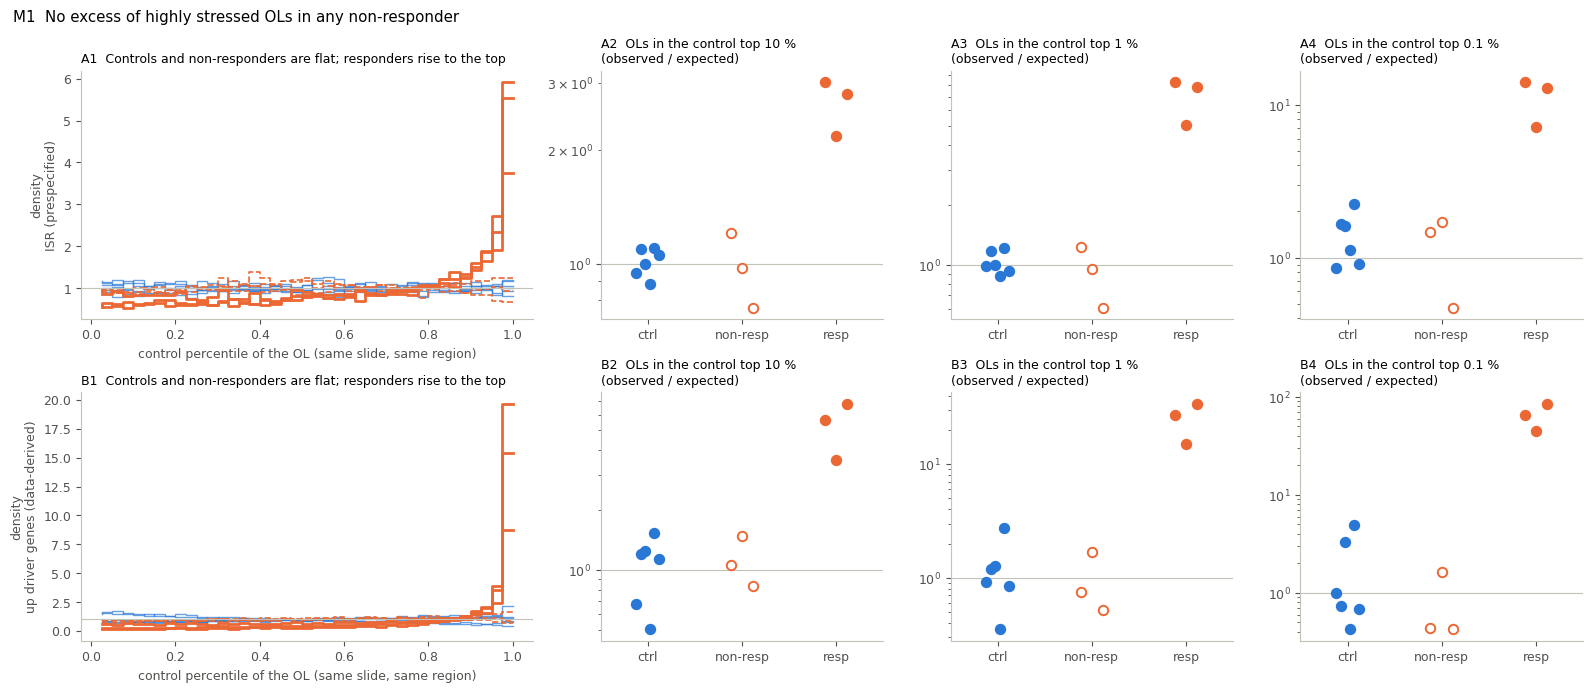

In [2]:
rows = []
for sc in SCORES:
    for s in order:
        u = ol.loc[ol.sample_id == s, f"u_{sc}"]
        rows.append({"score": sc, "sample_id": s, "group": grp[s], "n_ol": int(u.notna().sum()), "mean_pct": u.mean(),
                     "excess_q90": mo.tail_enrichment(u, 0.90), "excess_q99": mo.tail_enrichment(u, 0.99),
                     "excess_q999": mo.tail_enrichment(u, 0.999), "responding_lb": mo.responding_fraction_lb(u)})
tails = save_table(pd.DataFrame(rows).round(3), "tail_enrichment", index=False)
display(tails[tails.score == "isr"].set_index("sample_id"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7), gridspec_kw={"width_ratios": [1.6, 1, 1, 1]})
for row, sc in enumerate(SCORES):
    ax = axes[row, 0]; bins = np.linspace(0, 1, 41)
    for s in order:
        h, _ = np.histogram(ol.loc[ol.sample_id == s, f"u_{sc}"].dropna(), bins=bins, density=True)
        ax.step(bins[1:], h, where="pre", **LINE[grp[s]])
    ax.axhline(1, color=AXIS, lw=0.8); ax.set_xlabel("control percentile of the OL (same slide, same region)")
    ax.set_ylabel(f"density\n{SCORES[sc]}"); ax.set_title(f"{'AB'[row]}1  Controls and non-responders are flat; responders rise to the top", fontsize=9)
    t = tails[tails.score == sc].set_index("sample_id")
    for j, (col, lab) in enumerate([("excess_q90", "top 10 %"), ("excess_q99", "top 1 %"), ("excess_q999", "top 0.1 %")]):
        dots(axes[row, j + 1], t[col], f"{'AB'[row]}{j + 2}  OLs in the control {lab}\n(observed / expected)", ref=1)
        axes[row, j + 1].set_yscale("log")
fig.suptitle("M1  No excess of highly stressed OLs in any non-responder", x=0.01, ha="left")
fig.tight_layout(); save(fig, "M1_percentiles_and_tails")

**A.** In controls (scored against the other controls of their slide) and in all three non-responders the per-cell
percentiles are flat: the share of OLs in the control top 1 % is 0.6-1.2x expected (controls 0.9-1.2x), and in the
top 0.1 % 0.5-1.7x (controls 0.9-2.2x). Responders have 5-8x (ISR) and 15-34x (driver genes) the expected share in
the top 1 %. The driver-gene score separates the responders more (it was selected on them) but shows no excess in
non-responders either. RB4630, the borderline mouse (P(responder) = 0.17), is at the top of the control range for
ISR (1.2x) but not for the driver genes (0.7x).

## B. Any regional pocket?

region,Thalamus,Fiber tracts,Hypothalamus,Striatum,Cortex,Hippocampus
fewest OLs in a section,1409,2779,966,726,990,88


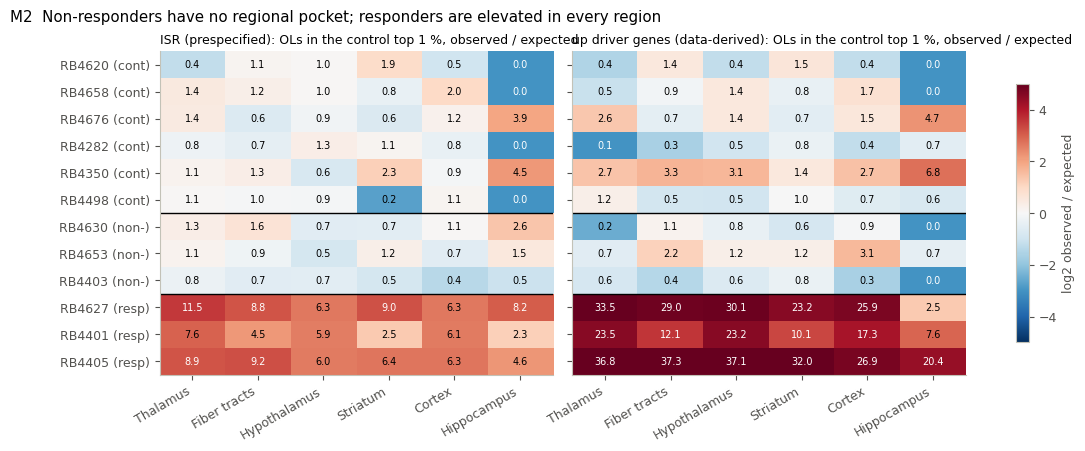

In [3]:
REG = ["Thalamus", "Fiber tracts", "Hypothalamus", "Striatum", "Cortex", "Hippocampus"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"wspace": 0.05})
for ax, sc in zip(axes, SCORES):
    t = ol.groupby(["sample_id", "region"])[f"u_{sc}"].apply(lambda u: mo.tail_enrichment(u, 0.99)).unstack().loc[order, REG]
    n = ol.groupby(["sample_id", "region"]).size().unstack().loc[order, REG]
    save_table(t.round(3), f"region_excess_q99_{sc}")
    im = ax.imshow(np.log2(t.clip(lower=0.125)), cmap="RdBu_r", vmin=-5, vmax=5, aspect="auto")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.iat[i, j]:.1f}", ha="center", va="center", fontsize=7, color="k" if abs(np.log2(max(t.iat[i, j], .125))) < 3 else "w")
    ax.set_xticks(range(len(REG)), REG, rotation=30, ha="right"); ax.set_yticks(range(len(order)), [f"{s} ({grp[s][:4]})" for s in order] if ax is axes[0] else [])
    for y in (len(ctrl) - 0.5, len(ctrl) + len(nonr) - 0.5): ax.axhline(y, color="k", lw=1)
    ax.set_title(f"{SCORES[sc]}: OLs in the control top 1 %, observed / expected", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8, label="log2 observed / expected")
fig.suptitle("M2  Non-responders have no regional pocket; responders are elevated in every region", x=0.01, ha="left")
save(fig, "M2_region_tails")
display(n.min().rename("fewest OLs in a section").to_frame().T)

**B.** No region of any non-responder reaches the responder range: the highest non-responder cell is RB4630 fibre
tracts at 1.6x (ISR) and RB4653 cortex at 3.1x (driver genes), both inside what controls show (up to 2.3x / 3.3x
outside the hippocampus, which has few OLs per section, so a few cells swing the ratio). In responders the excess is present in
every region, strongest in thalamus and fibre tracts, matching finding 4.

## C. How small a responding share could we have detected?

isr           drivers_up          
                      0.90      0.99       0.90      0.99
planted_fraction                                         
0.00              0.166667  0.166667   0.166667  0.166667
0.01              0.425000  0.333333   0.166667  0.166667
0.02              0.500000  0.650000   0.166667  0.166667
0.03              0.675000  0.983333   0.166667  0.166667
0.05              1.000000  1.000000   0.241667  0.166667
0.10              1.000000  1.000000   0.666667  0.891667
0.20              1.000000  1.000000   1.000000  1.000000

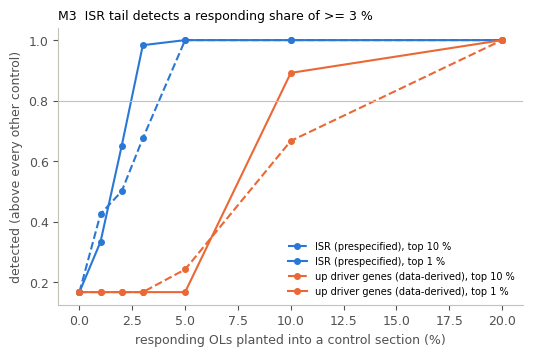

In [4]:
FRACS = [0.0, 0.01, 0.02, 0.03, 0.05, 0.1, 0.2]
det = {}
for sc in SCORES:
    comp = mo.responding_component(ol.loc[ol.sample_id.isin(resp), f"u_{sc}"].to_numpy())
    uc = {s: ol.loc[ol.sample_id == s, f"u_{sc}"].to_numpy() for s in ctrl}
    for q in (0.9, 0.99):
        det[(sc, q)] = mo.spike_in_detection(uc, comp, FRACS, q=q, n_rep=20)
det = save_table(pd.DataFrame(det).rename_axis("planted_fraction"), "spike_in_detection")
display(det)
fig, ax = plt.subplots(figsize=(6, 3.6))
for (sc, q), v in det.items():
    ax.plot(np.array(FRACS) * 100, v, marker="o", ms=4, color=BLUE if sc == "isr" else ORANGE, ls="-" if q == 0.99 else "--",
            label=f"{SCORES[sc]}, top {100 - 100 * q:.0f} %")
ax.axhline(0.8, color=AXIS, lw=0.8); ax.set_xlabel("responding OLs planted into a control section (%)")
ax.set_ylabel("detected (above every other control)"); ax.legend(frameon=False, fontsize=7)
ax.set_title("M3  ISR tail detects a responding share of >= 3 %", fontsize=9)
save(fig, "M3_detection_power")

**C.** Planting responder-like OLs into control sections, the ISR top-1 % excess flags the section in ~98 % of
trials once 3 % of its OLs respond, and always at 5 % (the 0 % row, 1/6, is the chance that a control is itself
the highest of the six). The driver-gene score is less sensitive here because one
control (RB4350) has a high tail; it needs ~10-20 %. So a non-responder could hide at most ~3 % responding OLs, i.e.
less than a tenth of the share seen in responders (D). The planted cells are drawn from a crude estimate of the
responding component (responder percentiles minus their uniform floor), so treat 3 % as approximate.

## D. What share of OLs respond in each mouse?

score,drivers_up,isr,group
sample_id,,,
RB4620,0.00,0.00,control
RB4658,0.10,0.03,control
RB4676,0.16,0.07,control
RB4282,-0.00,0.00,control
RB4350,0.14,0.01,control
RB4498,0.15,0.06,control
RB4630,0.05,0.05,non-responder
RB4653,0.17,0.00,non-responder
RB4403,0.04,-0.00,non-responder


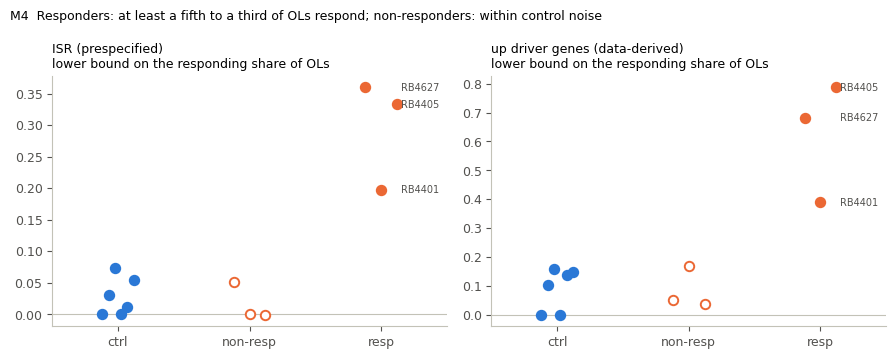

In [5]:
lb = tails.pivot(index="sample_id", columns="score", values="responding_lb").loc[order]
save_table(lb.round(3), "responding_fraction_lower_bound")
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, sc in zip(axes, SCORES):
    dots(ax, lb[sc], f"{SCORES[sc]}\nlower bound on the responding share of OLs", ref=0)
    for s in resp: ax.annotate(s, (2.15, lb.loc[s, sc]), fontsize=7, color=INK2, va="center")
fig.suptitle("M4  Responders: at least a fifth to a third of OLs respond; non-responders: within control noise", x=0.01, ha="left", fontsize=9)
fig.tight_layout(); save(fig, "M4_responding_fraction")
display(lb.round(2).assign(group=grp))

**D.** The lower bound on the responding share (from the ISR percentiles) is 0.20-0.36 in responders against 0-0.07
in controls and non-responders; with the sharper driver-gene score it is 0.39-0.79 against 0-0.16 in controls
and 0.04-0.17 in non-responders. These are
lower bounds: a single-cell ISR score from ~10 genes is noisy, so many responding cells sit inside the control range.
A large share of OLs respond in responders, in every region.

## Summary

* **Non-responders are not mosaic**: no excess of highly stressed OLs overall or in any region, and the ISR tail would
  have caught >= 3 % responding OLs. If induction failed, it failed almost completely, not in a patchy way.
* **Responders**: at least 20-36 % (ISR) and plausibly 40-80 % (driver genes) of OLs respond, in every region.
* All-or-none per mouse at the cell level too, which fits a per-animal event (failed induction, or a threshold
  crossed in the whole brain) rather than a stochastic per-cell one. RB4630 remains the mouse to check at the bench.